In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv('heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [6]:
#Viewing shape of dataset
print(df.shape)

(918, 12)


In [9]:
#Viewing column datatypes
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB
None


In [8]:
#Inspecting target class balance -> heart disease variable
print(df['HeartDisease'].value_counts(normalize=True)*100)

HeartDisease
1    55.337691
0    44.662309
Name: proportion, dtype: float64


In [10]:
df.describe()
#0 values in cholesterol and resting BP mean unrecorded data.

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [12]:
#To fix unrecorded data, we make 0 values for those two variables as NaN
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)
df['RestingBP'] = df['RestingBP'].replace(0, np.nan)
#Fill missing values with median
df['Cholesterol'] = df['Cholesterol'].fillna(df['Cholesterol'].median())
df['RestingBP'] = df['RestingBP'].fillna(df['RestingBP'].median())

#Check if changes were made
print("Missing values in Cholesterol:", df['Cholesterol'].isnull().sum())
print("Missing values in RestingBP:", df['RestingBP'].isnull().sum())

Missing values in Cholesterol: 0
Missing values in RestingBP: 0


In [16]:
#Creating new features to help ML model

# Feature 1: Heart Rate Reserve (Max possible HR based on age vs. achieved max HR)
df['HR_Reserve'] = (220 - df['Age']) - df['MaxHR']

# Feature 2: High-Risk Combination Flag 
# (High fasting blood sugar AND exercise-induced angina)
df['High_Risk_Combo'] = ((df['FastingBS'] == 1) & (df['ExerciseAngina'] == 'Y')).astype(int)

# Feature 3: Blood Pressure Stages (Normal <120, Elevated 120-129, High >=130)
df['BP_Category'] = pd.cut( #<-- turns continuous numbers into discrete groups (bins)
    df['RestingBP'],
    bins=[0,120,130,300],
    labels=['Normal','Elevated','High']
)

In [17]:
#One hot encoding - categorical to numerical
X = df.drop(columns=['HeartDisease'])
y = df['HeartDisease']

X = pd.get_dummies(X, drop_first=True)

print(X.shape)
print(X.columns.tolist())

(918, 19)
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HR_Reserve', 'High_Risk_Combo', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up', 'BP_Category_Elevated', 'BP_Category_High']


In [19]:
%pip install xgboost shap

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   --- ------------------------------------ 3.9/48.9 MB 23.9 MB/s eta 0:00:02
   ------- -------------------------------- 8.9/48.9 MB 23.5 MB/s eta 0:00:02
   ---------- ----------------------------- 13.1/48.9 MB 22.1 MB/s eta 0:00:02
   --------------- ------------------------ 18.6/48.9 MB 22.9 MB/s eta 0:00:02
   ------------------ --------------------- 23.1/48.9 MB 22.9 MB/s eta 0:00:02
   ------------------- -------------------- 24.1/48.9 MB 19.6 MB/s eta 0:00:02
   --------------------- ------------------ 26.0/48.9 MB 18.2 MB/s eta 0:00:02
   ---------------------- ----------------- 27.3/48.9 MB 16.7 MB/s eta 0:00:02
   ----------------------- ---------------- 28.6/48.9 MB 15.6 MB/s eta 0:00:02
   ----------------------- ---------------- 29.4/48.9 MB 14.1 MB/s eta 0:00:02
   ------------------------- -------------- 30.7/48.9 MB 13.1 MB/s eta 0:00:02
   ---------------------------- ----------- 35.4/48.9 MB 13.9 M

In [20]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

In [22]:
#Split our data into 80% training data and 20% test data, train an XGBoost Classifier, and evaluate performance using Recall 
#(how many real heart disease cases we correctly caught) and ROC-AUC

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#Training XGBoost Model
model = xgb.XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    eval_metric='logloss',
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

print(classification_report(y_test, y_pred))
print(roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.85      0.85      0.85        82
           1       0.88      0.88      0.88       102

    accuracy                           0.87       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.87      0.87       184

0.9267097082735534


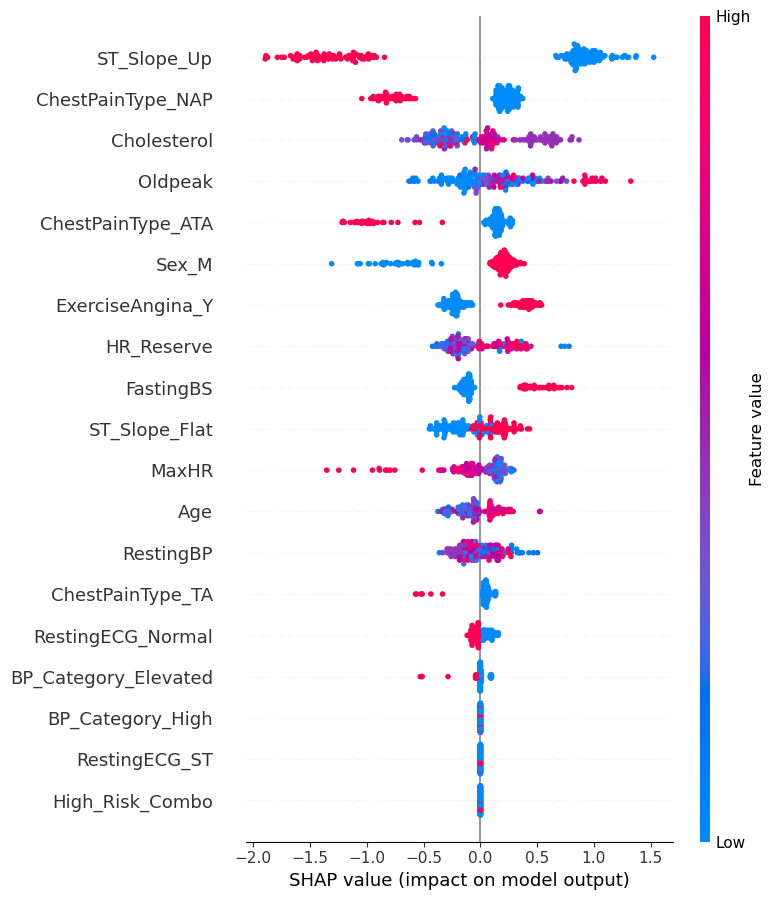

In [24]:
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test)

In [31]:
import joblib
import os

# saving my trained model and column structure
joblib.dump(model, 'heart_model.pkl')
joblib.dump(X_train.columns.tolist(), 'model_columns.pkl')

# printing the exact folder path where they were saved
print("Files saved successfully in:")
print(os.getcwd())

Files saved successfully in:
C:\Users\sukhl


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score

models = {
    "Logistic Regression (Baseline)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=150, random_state=42),
    "XGBoost (Final)": model  # My already-trained XGBoost model
}

results = []
for name, clf in models.items():
    if name != "XGBoost (Final)":
        clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    probs = clf.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Recall (Sensitivity)": round(recall_score(y_test, preds), 3),
        "Precision": round(precision_score(y_test, preds), 3),
        "F1-Score": round(f1_score(y_test, preds), 3),
        "ROC-AUC": round(roc_auc_score(y_test, probs), 3)
    })

comparison_df = pd.DataFrame(results)
print(comparison_df.to_string(index=False))

                         Model  Recall (Sensitivity)  Precision  F1-Score  ROC-AUC
Logistic Regression (Baseline)                 0.912      0.894     0.903    0.931
                 Random Forest                 0.863      0.889     0.876    0.926
               XGBoost (Final)                 0.882      0.882     0.882    0.927


In [27]:
from sklearn.metrics import recall_score, precision_score, f1_score

y_prob = model.predict_proba(X_test)[:, 1]

print("--- Clinical Threshold Sensitivity Analysis ---")
for thresh in [0.50, 0.45, 0.40, 0.35]:
    custom_preds = (y_prob >= thresh).astype(int)
    rec = recall_score(y_test, custom_preds)
    prec = precision_score(y_test, custom_preds)
    f1 = f1_score(y_test, custom_preds)
    print(f"Threshold {thresh:.2f} | Recall: {rec:.3f} | Precision: {prec:.3f} | F1: {f1:.3f}")

--- Clinical Threshold Sensitivity Analysis ---
Threshold 0.50 | Recall: 0.882 | Precision: 0.882 | F1: 0.882
Threshold 0.45 | Recall: 0.902 | Precision: 0.868 | F1: 0.885
Threshold 0.40 | Recall: 0.931 | Precision: 0.864 | F1: 0.896
Threshold 0.35 | Recall: 0.941 | Precision: 0.850 | F1: 0.893


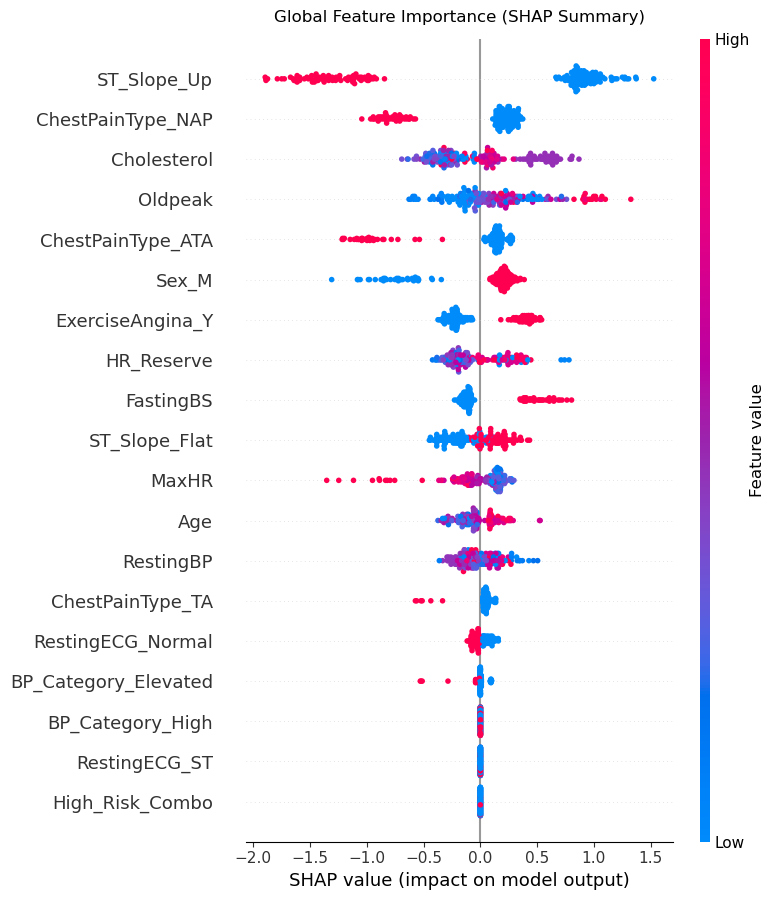

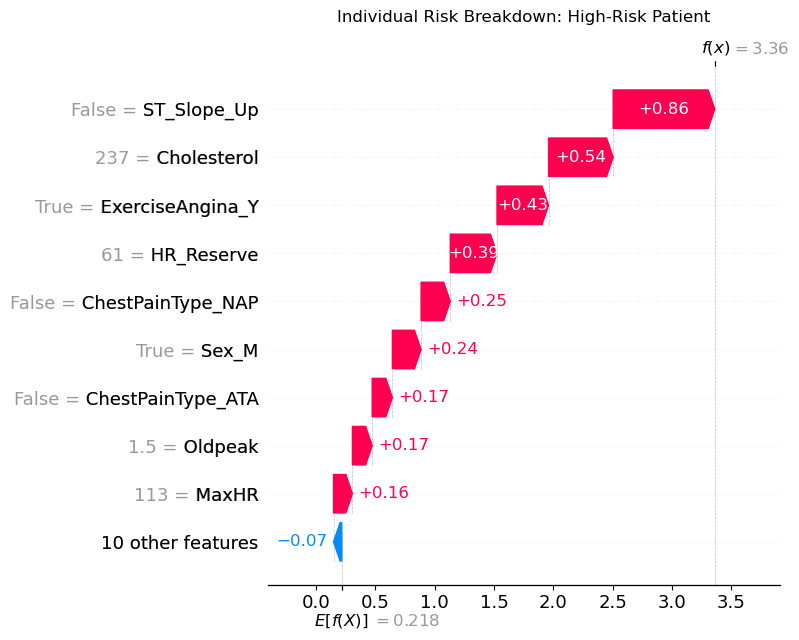

Saved 'shap_summary.png' and 'shap_patient_waterfall.png' to my project folder!


In [29]:
import matplotlib.pyplot as plt
import shap

# saving Global SHAP Summary Plot
plt.figure()
shap.summary_plot(shap_values, X_test, show=False)
plt.title("Global Feature Importance (SHAP Summary)", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

# saving Individual High-Risk Patient Waterfall Plot
high_risk_idx = np.where(y_test == 1)[0][0]
plt.figure()
shap.plots.waterfall(shap_values[high_risk_idx], show=False)
plt.title("Individual Risk Breakdown: High-Risk Patient", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("shap_patient_waterfall.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved 'shap_summary.png' and 'shap_patient_waterfall.png' to my project folder!")